<a href="https://colab.research.google.com/github/Osuni-99/Adaptive-AI-DLP-Research/blob/main/notebooks/07_AI_Classification_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:

# ==========================================
# Notebook 07 - AI-Based Data Classification
# Section 01: Environment Setup
# ==========================================

import os
import re
import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

print("Notebook 07 Started Successfully")
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)


Notebook 07 Started Successfully
Pandas Version: 2.2.3
NumPy Version: 2.4.6


In [16]:

# ==========================================
# Section 02: Dataset Availability Check
# ==========================================

from pathlib import Path

base_path = Path("datasets")

if base_path.exists():

    print("Dataset folder found!")

    for file in base_path.rglob("*.csv"):
        print(file)

else:
    print("Dataset folder not found.")
    print("Please check your Google Drive or Colab storage.")


Dataset folder not found.
Please check your Google Drive or Colab storage.


In [17]:
# ==========================================
# Section 03: Google Drive Connection
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

print("Google Drive Connected Successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive Connected Successfully!


In [18]:
# ==========================================
# Section 04: Search Dataset CSV Files
# ==========================================

from pathlib import Path

drive_path = Path("/content/drive/MyDrive")

csv_files = list(drive_path.rglob("*.csv"))

if csv_files:
    print("CSV Files Found:", len(csv_files))

    for file in csv_files:
        print(file)

else:
    print("No CSV files found in Google Drive.")

CSV Files Found: 11
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final/dataset_manifest.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final/dataset_statistics.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final/dataset_catalog.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/enron/enron_standardized.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/funsd/funsd_raw.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/cord/cord_sample.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/cord/cord_standardized.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/sroie/sroie_standardized.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Document_Templates.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/dataset_metadata.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_datas

In [19]:
# ==========================================
# Section 05: Check Colab Storage
# ==========================================

import os
from pathlib import Path

print("Current Working Directory:", os.getcwd())

print("\nFiles in current directory:")
for item in Path(".").iterdir():
    print(item)

print("\nCSV files in /content:")
for file in Path("/content").rglob("*.csv"):
    print(file)

Current Working Directory: /content

Files in current directory:
.config
drive
sample_data

CSV files in /content:
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/california_housing_train.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final/dataset_manifest.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final/dataset_statistics.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final/dataset_catalog.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/enron/enron_standardized.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/funsd/funsd_raw.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/cord/cord_sample.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/cord/cord_standardized.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/sroie/sroie_standardized.csv
/content

In [20]:
# ==========================================
# Section 05: Load and Inspect Datasets
# ==========================================

from pathlib import Path
import pandas as pd

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research"
)

DATASET_PATH = PROJECT_PATH / "datasets"

dataset_files = {
    "Enron": DATASET_PATH / "public/enron/enron_standardized.csv",
    "FUNSD": DATASET_PATH / "public/funsd/funsd_raw.csv",
    "CORD": DATASET_PATH / "public/cord/cord_standardized.csv",
    "SROIE": DATASET_PATH / "public/sroie/sroie_standardized.csv"
}

for name, path in dataset_files.items():

    print("\n" + "=" * 50)
    print("DATASET:", name)

    if path.exists():

        print("File size:",
              round(path.stat().st_size / (1024 * 1024), 2), "MB")

        preview = pd.read_csv(path, nrows=5)

        print("Columns:", list(preview.columns))
        print("\nSample records:")
        display(preview.head(2))

    else:
        print("Dataset not found:", path)


DATASET: Enron
File size: 47.58 MB
Columns: ['Document ID', 'Subject', 'Content', 'Document Type', 'Department', 'Industry', 'Classification', 'Risk', 'Sensitive Entities', 'Leakage Score', 'Format']

Sample records:


,Document ID,Subject,Content,Document Type,Department,Industry,Classification,Risk,Sensitive Entities,Leakage Score,Format
0,33214,any software just for 15 $ - 99 $,understanding oem software\nlead me not into t...,Email,Corporate,Enterprise,UNKNOWN,UNKNOWN,[],-1,EMAIL
1,11929,perspective on ferc regulatory action client c...,"19 th , 2 : 00 pm edt\nperspective on ferc reg...",Email,Corporate,Enterprise,UNKNOWN,UNKNOWN,[],-1,EMAIL



DATASET: FUNSD
File size: 33.97 MB
Columns: ['id', 'words', 'bboxes', 'ner_tags', 'image']

Sample records:


,id,words,bboxes,ner_tags,image
0,0,['R&D' ':' 'Suggestion:' 'Date:' 'Licensee' 'Y...,"[array([383, 91, 493, 175]) array([287, 316, ...",[0 3 3 3 5 3 3 0 1 2 2 2 2 2 3 4 4 4 4 5 6 6 6...,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...
1,1,['Brand:' 'Style:' 'PHOENIX' 'Company:' 'Count...,"[array([ 99, 129, 154, 139]) array([ 95, 141, ...",[3 3 5 3 3 3 5 5 1 1 3 3 3 3 5 5 5 5 3 3 3 3 3...,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...



DATASET: CORD
File size: 0.03 MB
Columns: ['Document ID', 'Document Type', 'Department', 'Industry', 'Format', 'Classification', 'Risk', 'Sensitive Entities', 'Leakage Score']

Sample records:


,Document ID,Document Type,Department,Industry,Format,Classification,Risk,Sensitive Entities,Leakage Score
0,0,Receipt,Finance,Retail,Image + JSON,Pending,Pending,Not Processed,-1
1,1,Receipt,Finance,Retail,Image + JSON,Pending,Pending,Not Processed,-1



DATASET: SROIE
File size: 0.05 MB
Columns: ['Document ID', 'Image File', 'Document Type', 'Department', 'Industry', 'Classification', 'Risk', 'Sensitive Entities', 'Leakage Score', 'Format']

Sample records:


,Document ID,Image File,Document Type,Department,Industry,Classification,Risk,Sensitive Entities,Leakage Score,Format
0,X00016469612,X00016469612.jpg,Receipt,Finance,Retail,Pending,Pending,Not Processed,-1,JPG
1,X00016469619,X00016469619.jpg,Receipt,Finance,Retail,Pending,Pending,Not Processed,-1,JPG


In [21]:
from pathlib import Path

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research"
)

DATASET_PATH = PROJECT_PATH / "datasets"

print("CUSTOM DATASET FILES")
print("=" * 50)

for folder in [
    DATASET_PATH / "custom",
    DATASET_PATH / "synthetic",
    DATASET_PATH / "generated",
    DATASET_PATH / "final"
]:
    if folder.exists():
        print(f"\nFolder: {folder}")

        for file in folder.rglob("*"):
            if file.is_file() and file.suffix.lower() in [
                ".csv", ".json", ".xlsx"
            ]:
                size_mb = file.stat().st_size / (1024 * 1024)
                print(f"{file.name} - {size_mb:.2f} MB")

CUSTOM DATASET FILES

Folder: /content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom
Document_Templates.csv - 0.00 MB
dataset_metadata.csv - 0.53 MB
salary_slip.json - 0.00 MB
invoice.json - 0.00 MB
contract.json - 0.00 MB
bank_statement.json - 0.00 MB
leave_form.json - 0.00 MB
hr_policy.json - 0.00 MB
meeting_minutes.json - 0.00 MB
nda.json - 0.00 MB
tax_report.json - 0.00 MB
firewall_configuration.json - 0.00 MB
source_code.json - 0.00 MB
marketing_brochure.json - 0.00 MB
dataset_metadata.csv - 0.01 MB

Folder: /content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final
dataset_manifest.csv - 0.00 MB
dataset_statistics.csv - 0.00 MB
dataset_catalog.csv - 0.00 MB


In [22]:
from pathlib import Path

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research"
)

print("SEARCHING PROJECT FILES")
print("=" * 60)

for file in PROJECT_PATH.rglob("*"):
    if file.is_file() and file.suffix.lower() in [
        ".csv", ".json", ".ipynb"
    ]:
        size_mb = file.stat().st_size / (1024 * 1024)

        print(
            f"{file.relative_to(PROJECT_PATH)} "
            f"| {size_mb:.2f} MB"
        )

SEARCHING PROJECT FILES
datasets/final/dataset_manifest.csv | 0.00 MB
datasets/final/dataset_statistics.csv | 0.00 MB
datasets/final/dataset_catalog.csv | 0.00 MB
datasets/public/enron/enron_standardized.csv | 47.58 MB
datasets/public/funsd/funsd_raw.csv | 33.97 MB
datasets/public/cord/cord_sample.csv | 3201.00 MB
datasets/public/cord/cord_standardized.csv | 0.03 MB
datasets/public/sroie/sroie_standardized.csv | 0.05 MB
datasets/custom/multimodal/Document_Templates.csv | 0.00 MB
datasets/custom/multimodal/dataset_metadata.csv | 0.53 MB
datasets/custom/multimodal/templates/salary_slip.json | 0.00 MB
datasets/custom/multimodal/templates/invoice.json | 0.00 MB
datasets/custom/multimodal/templates/contract.json | 0.00 MB
datasets/custom/multimodal/templates/bank_statement.json | 0.00 MB
datasets/custom/multimodal/templates/leave_form.json | 0.00 MB
datasets/custom/multimodal/templates/hr_policy.json | 0.00 MB
datasets/custom/multimodal/templates/meeting_minutes.json | 0.00 MB
datasets/cust

In [23]:
from pathlib import Path

DRIVE_PATH = Path("/content/drive/MyDrive")

print("SEARCHING NOTEBOOK 01 AND 04")
print("=" * 60)

for file in DRIVE_PATH.rglob("*.ipynb"):
    name = file.name.lower()

    if (
        "01" in name
        or "04" in name
        or "dataset" in name
    ):
        print(file)

SEARCHING NOTEBOOK 01 AND 04
/content/drive/MyDrive/Colab Notebooks/Copy of 04_Multimodal_Dataset_Generator.ipynb
/content/drive/MyDrive/Colab Notebooks/Task 04.ipynb
/content/drive/MyDrive/Colab Notebooks/05_Public_Dataset_Integration.ipynb
/content/drive/MyDrive/Colab Notebooks/01_SME_Dataset_Generator.ipynb
/content/drive/MyDrive/Colab Notebooks/04_Multimodal_Dataset_Generator.ipynb


In [24]:
from pathlib import Path

PROJECT_PATH = Path("/content/drive/MyDrive/Adaptive_AI_DLP_Research")

files_to_check = [
    PROJECT_PATH / "datasets/custom/SME_DLP_Dataset.csv",
    PROJECT_PATH / "datasets/custom/dataset_metadata.csv",
    PROJECT_PATH / "datasets/custom/multimodal/dataset_metadata.csv"
]

for file in files_to_check:
    print("\nFile:", file)
    print("Exists:", file.exists())

    if file.exists():
        print("Size:", round(file.stat().st_size / (1024 * 1024), 2), "MB")


File: /content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/SME_DLP_Dataset.csv
Exists: False

File: /content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/dataset_metadata.csv
Exists: False

File: /content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/dataset_metadata.csv
Exists: True
Size: 0.53 MB


In [25]:
from pathlib import Path

PROJECT_PATH = Path("/content/drive/MyDrive/Adaptive_AI_DLP_Research")

print("Searching for SME dataset...")

for file in PROJECT_PATH.rglob("*.csv"):
    if "SME" in file.name.upper() or "DLP" in file.name.upper():
        print(file)

Searching for SME dataset...


In [26]:
from pathlib import Path

DRIVE_PATH = Path("/content/drive/MyDrive")

print("Searching entire Google Drive...")

matches = []

for file in DRIVE_PATH.rglob("*.csv"):
    if "SME_DLP_Dataset" in file.name:
        matches.append(file)

if matches:
    for file in matches:
        print("FOUND:", file)
else:
    print("SME_DLP_Dataset.csv NOT FOUND in MyDrive")

Searching entire Google Drive...
SME_DLP_Dataset.csv NOT FOUND in MyDrive


In [28]:
# ============================================================
# LOAD CUSTOM DATASETS
# ============================================================

import pandas as pd
from pathlib import Path

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research"
)

# Dataset paths
SME_PATH = PROJECT_PATH / "datasets/custom/SME_DLP_Dataset.csv"

MULTIMODAL_PATH = (
    PROJECT_PATH /
    "datasets/custom/multimodal/dataset_metadata.csv"
)

# Load datasets
sme_df = pd.read_csv(SME_PATH)

multimodal_df = pd.read_csv(MULTIMODAL_PATH)

# Display dataset information
print("=" * 60)
print("DATASET LOADING RESULTS")
print("=" * 60)

print("\nSME DATASET")
print("Records:", len(sme_df))
print("Columns:", len(sme_df.columns))
print("Classification Distribution:")
print(sme_df["Classification"].value_counts())

print("\nMULTIMODAL DATASET")
print("Records:", len(multimodal_df))
print("Columns:", len(multimodal_df.columns))
print("Classification Distribution:")
print(multimodal_df["Classification"].value_counts())

print("\n" + "=" * 60)
print("BOTH DATASETS LOADED SUCCESSFULLY!")
print("=" * 60)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/SME_DLP_Dataset.csv'

In [29]:
from pathlib import Path
import os

# Google Drive path
DRIVE = Path("/content/drive/MyDrive")

PROJECT = DRIVE / "Adaptive_AI_DLP_Research"

print("=" * 60)
print("GOOGLE DRIVE DIAGNOSTIC")
print("=" * 60)

print("Drive mounted:", DRIVE.exists())
print("Project folder exists:", PROJECT.exists())

# Check custom folder
CUSTOM = PROJECT / "datasets" / "custom"

print("\nCustom folder exists:", CUSTOM.exists())

if CUSTOM.exists():
    print("\nFiles inside custom folder:")

    for file in CUSTOM.rglob("*"):
        if file.is_file():
            print(file)

# Search entire MyDrive for SME dataset
print("\n" + "=" * 60)
print("SEARCHING FOR SME DATASET")
print("=" * 60)

found = []

for file in DRIVE.rglob("SME_DLP_Dataset.csv"):
    found.append(file)
    print("FOUND:", file)

if not found:
    print("SME_DLP_Dataset.csv NOT FOUND")

# Verify multimodal dataset
MULTIMODAL = (
    CUSTOM / "multimodal" / "dataset_metadata.csv"
)

print("\nMultimodal dataset exists:", MULTIMODAL.exists())

print("\nDIAGNOSTIC COMPLETED")

Streaming output truncated to the last 5000 lines.
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Marketing_Brochure/Marketing_Brochure_053.docx
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Marketing_Brochure/Marketing_Brochure_053.pdf
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Marketing_Brochure/Marketing_Brochure_053.png
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Marketing_Brochure/Marketing_Brochure_054.txt
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Marketing_Brochure/Marketing_Brochure_054.docx
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Marketing_Brochure/Marketing_Brochure_054.pdf
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Marketing_Brochure/Marketing_Brochure_054.png
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Marketing_Brochure/Market

In [30]:
from pathlib import Path

base = Path("/content/drive/MyDrive/Adaptive_AI_DLP_Research")

for name in [
    "SME_DLP_Dataset.csv",
    "dataset_metadata.csv"
]:
    matches = list(base.rglob(name))
    print(f"\n{name}:")
    if matches:
        for path in matches:
            print("FOUND:", path)
    else:
        print("NOT FOUND")


SME_DLP_Dataset.csv:
NOT FOUND

dataset_metadata.csv:
FOUND: /content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/dataset_metadata.csv
FOUND: /content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/dataset_metadata.csv


In [31]:
import os

base_path = "/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom"

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Document_Templates.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/dataset_metadata.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/dataset_metadata.csv


In [32]:
# ==========================================
# Notebook 07 - Section 06
# Load Custom Datasets
# ==========================================

from pathlib import Path
import pandas as pd

# Project directory
PROJECT_PATH = Path(
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research"
)

# Dataset paths
SME_PATH = (
    PROJECT_PATH / "datasets/custom/SME_DLP_Dataset.csv"
)

MULTIMODAL_PATH = (
    PROJECT_PATH / "datasets/custom/multimodal/dataset_metadata.csv"
)

# Check file availability
print("SME Dataset:", SME_PATH.exists())
print("Multimodal Dataset:", MULTIMODAL_PATH.exists())

# Load datasets
if SME_PATH.exists():
    sme_df = pd.read_csv(SME_PATH)
    print("\nSME Dataset Loaded Successfully!")
    print("Total Records:", len(sme_df))
    print("Columns:", list(sme_df.columns))

if MULTIMODAL_PATH.exists():
    multimodal_df = pd.read_csv(MULTIMODAL_PATH)
    print("\nMultimodal Dataset Loaded Successfully!")
    print("Total Records:", len(multimodal_df))
    print("Columns:", list(multimodal_df.columns))

# Display sample records
print("\nSME Dataset Preview:")
display(sme_df.head())

print("\nMultimodal Dataset Preview:")
display(multimodal_df.head())

SME Dataset: False
Multimodal Dataset: True

Multimodal Dataset Loaded Successfully!
Total Records: 4800
Columns: ['Document ID', 'File Name', 'Document Type', 'Department', 'Industry', 'Classification', 'Risk', 'Sensitive Entities', 'Leakage Score', 'Format']

SME Dataset Preview:


NameError: name 'sme_df' is not defined

In [33]:
# ==========================================
# Find SME Dataset in Google Drive
# ==========================================

from pathlib import Path

DRIVE_PATH = Path("/content/drive/MyDrive")

matches = list(
    DRIVE_PATH.rglob("SME_DLP_Dataset.csv")
)

print("SME Dataset Files Found:", len(matches))

for path in matches:
    print(path)

SME Dataset Files Found: 0


In [34]:
# ==========================================
# Notebook 07 - Load Custom Datasets
# ==========================================

from pathlib import Path
import pandas as pd

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research"
)

SME_PATH = (
    PROJECT_PATH / "datasets/custom/SME_DLP_Dataset.csv"
)

MULTIMODAL_PATH = (
    PROJECT_PATH / "datasets/custom/multimodal/dataset_metadata.csv"
)

# Load datasets
sme_df = pd.read_csv(SME_PATH)
multimodal_df = pd.read_csv(MULTIMODAL_PATH)

# Display information
print("SME Dataset Loaded:", len(sme_df))
print("Multimodal Dataset Loaded:", len(multimodal_df))

print("\nSME Columns:")
print(list(sme_df.columns))

print("\nSME Classification Distribution:")
print(sme_df["Classification"].value_counts())

print("\nMultimodal Classification Distribution:")
print(multimodal_df["Classification"].value_counts())

print("\nSME Preview:")
display(sme_df.head())

print("\nMultimodal Preview:")
display(multimodal_df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/SME_DLP_Dataset.csv'

In [35]:
# ==========================================
# Verify Google Drive and Dataset Paths
# ==========================================

import os
from pathlib import Path

print("Drive mounted:", os.path.ismount("/content/drive"))

base_path = Path("/content/drive/MyDrive")

print("MyDrive exists:", base_path.exists())

project_path = base_path / "Adaptive_AI_DLP_Research"

print("Project folder exists:", project_path.exists())

# Check custom dataset folder
custom_path = project_path / "datasets" / "custom"

print("\nCustom folder exists:", custom_path.exists())

if custom_path.exists():
    print("\nFiles inside custom folder:")
    for item in custom_path.iterdir():
        print(item.name)

Drive mounted: True
MyDrive exists: True
Project folder exists: True

Custom folder exists: True

Files inside custom folder:
multimodal


In [36]:
import os
import pandas as pd

# Exact SME dataset path
SME_PATH = (
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research/"
    "datasets/custom/SME_DLP_Dataset.csv"
)

# Refresh Drive directory view
custom_folder = (
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom"
)

print("Files in custom folder:")
print(os.listdir(custom_folder))

print("\nSME file exists:", os.path.isfile(SME_PATH))

if os.path.isfile(SME_PATH):
    sme_df = pd.read_csv(SME_PATH)

    print("\nSME Dataset Loaded Successfully!")
    print("Records:", len(sme_df))
    print("Columns:", list(sme_df.columns))
    display(sme_df.head())

Files in custom folder:
['multimodal']

SME file exists: False


In [37]:
import os
import pandas as pd

SME_PATH = (
    "/content/drive/MyDrive/Adaptive_AI_DLP_Research/"
    "datasets/custom/SME_DLP_Dataset.csv"
)

print("File exists:", os.path.isfile(SME_PATH))

if os.path.isfile(SME_PATH):
    sme_df = pd.read_csv(SME_PATH)

    print("SME Dataset Loaded Successfully!")
    print("Total Records:", len(sme_df))
    print("Columns:", list(sme_df.columns))

    display(sme_df.head())
else:
    print("Dataset not found!")

File exists: False
Dataset not found!


In [38]:
from google.colab import drive

# Force remount Google Drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [39]:
import os

folder = (
    "/content/drive/MyDrive/"
    "Adaptive_AI_DLP_Research/datasets/custom"
)

print("Files found:")

for root, dirs, files in os.walk(folder):
    for file in files:
        print(os.path.join(root, file))

Streaming output truncated to the last 5000 lines.
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/Marketing_Brochure/Marketing_Brochure_051.txt
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/Marketing_Brochure/Marketing_Brochure_051.png
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/Marketing_Brochure/Marketing_Brochure_051.docx
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/Marketing_Brochure/Marketing_Brochure_051.pdf
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/Marketing_Brochure/Marketing_Brochure_052.txt
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/Marketing_Brochure/Marketing_Brochure_052.docx
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/Marketing_Brochure/Marketing_Brochure_052

In [40]:
import os

folder = "/content/drive/MyDrive/Adaptive_AI_DLP_Research"

print("CSV files found:")

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

CSV files found:
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/Document_Templates.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/dataset_metadata.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/multimodal/custom_dataset/dataset_metadata.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/enron/enron_standardized.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/funsd/funsd_raw.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/cord/cord_sample.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/cord/cord_standardized.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/public/sroie/sroie_standardized.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final/dataset_manifest.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final/dataset_statistics.csv
/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/final

In [43]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [44]:
import os

file_path = "/content/drive/MyDrive/Adaptive_AI_DLP_Research/datasets/custom/SME_DLP_Dataset.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")
else:
    print("Files in custom folder:")
    folder = os.path.dirname(file_path)
    print(os.listdir(folder))

File exists: False
Files in custom folder:
['multimodal']


In [50]:
import pandas as pd
import os

file_path = "/content/drive/MyDrive/SME_DLP_Dataset.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    sme_df = pd.read_csv(file_path)
    print("Dataset loaded:", sme_df.shape)

File exists: False


In [52]:
from google.colab import drive
import os
import pandas as pd

# Reset Google Drive connection
try:
    drive.flush_and_unmount()
except:
    pass

drive.mount('/content/drive')

# Search for SME dataset in the entire MyDrive
search_folder = "/content/drive/MyDrive"
found_file = None

for root, dirs, files in os.walk(search_folder):
    if "SME_DLP_Dataset.csv" in files:
        found_file = os.path.join(root, "SME_DLP_Dataset.csv")
        break

# Load dataset if found
if found_file:
    sme_df = pd.read_csv(found_file)

    print("SUCCESS! Dataset found and loaded.")
    print("File location:", found_file)
    print("Dataset shape:", sme_df.shape)
    print("\nClassification Distribution:")
    print(sme_df["Classification"].value_counts())

else:
    print("Dataset not found in this Google Drive.")
    print("\nMyDrive folders:")
    print(os.listdir(search_folder))

Mounted at /content/drive
Dataset not found in this Google Drive.

MyDrive folders:
['1 yr 1 sem papers', '1 SEM', 'Cyber Security', '..final exam papers', 'Committee Members Photographs (File responses)', 'Piano Covers', 'ICS', 'Reasearch Thesis - Isuranga Aiya', 'CS', '1 yr assignment', 'Resume', '4tos', '3 rd yr Final', 'Volunteers Registration (File responses)', 'Metasploitable2-Linux', 'Colab Notebooks', 'O.D. Abeywickrama.gdoc', 'MSc CS 2025 034 - Abeywickrama O.D..gdoc', 'OSUNI ABEYWICKRAMA CV_NEW.pdf', 'FGS MSc CS 034 - Log Book Maintain - Research.gsheet', 'Adaptive_AI_DLP_Research']


In [53]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

sme_df = pd.read_csv("SME_DLP_Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", sme_df.shape)
print("\nClassification Distribution:")
print(sme_df["Classification"].value_counts())

Saving SME_DLP_Dataset.csv to SME_DLP_Dataset.csv
Dataset loaded successfully!
Shape: (500, 12)

Classification Distribution:
Classification
Internal        130
Restricted      130
Confidential    123
Public          117
Name: count, dtype: int64


Dataset preprocessing

In [54]:
# ==========================================
# Section 06: SME Dataset Preparation
# ==========================================

import pandas as pd
import numpy as np

# Load SME dataset
sme_df = pd.read_csv("SME_DLP_Dataset.csv")

# Basic validation
print("Dataset Shape:", sme_df.shape)
print("\nMissing Values:")
print(sme_df.isnull().sum())

print("\nTarget Distribution:")
print(sme_df["Classification"].value_counts())

print("\nDataset Information:")
sme_df.info()

Dataset Shape: (500, 12)

Missing Values:
EmployeeID          0
Department          0
DocumentType        0
Classification      0
RiskLevel           0
LeakageScore        0
InternalNote      370
Name              247
NIC               247
Email             247
Salary            247
BankAccount       370
dtype: int64

Target Distribution:
Classification
Internal        130
Restricted      130
Confidential    123
Public          117
Name: count, dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   EmployeeID      500 non-null    int64  
 1   Department      500 non-null    object 
 2   DocumentType    500 non-null    object 
 3   Classification  500 non-null    object 
 4   RiskLevel       500 non-null    object 
 5   LeakageScore    500 non-null    int64  
 6   InternalNote    130 non-null    object 
 7   N

In [55]:
# ==========================================
# Section 07: Feature Selection
# ==========================================

# Target variable
TARGET = "Classification"

# Exclude direct target-derived fields and unique identifier
excluded_columns = [
    "EmployeeID",
    "Classification",
    "RiskLevel",
    "LeakageScore"
]

# Select input features
X = sme_df.drop(columns=excluded_columns)
y = sme_df[TARGET]

print("Selected Features:")
print(X.columns.tolist())

print("\nTarget Variable:", TARGET)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(y.unique())

Selected Features:
['Department', 'DocumentType', 'InternalNote', 'Name', 'NIC', 'Email', 'Salary', 'BankAccount']

Target Variable: Classification

Feature Shape: (500, 8)
Target Shape: (500,)

Target Classes:
['Public' 'Internal' 'Confidential' 'Restricted']


In [56]:
# Section 08: Feature Engineering

# Keep non-sensitive categorical features
X_model = sme_df[["Department", "DocumentType"]].copy()

# Create presence indicators for sensitive fields
sensitive_columns = [
    "InternalNote",
    "Name",
    "NIC",
    "Email",
    "Salary",
    "BankAccount"
]

for col in sensitive_columns:
    X_model[col + "_Present"] = sme_df[col].notna().astype(int)

# Target variable
y = sme_df["Classification"].copy()

print("Engineered Features:")
print(X_model.head())

print("\nFeature Shape:", X_model.shape)
print("\nTarget Distribution:")
print(y.value_counts())

Engineered Features:
  Department     DocumentType  InternalNote_Present  Name_Present  \
0         IT  Employee Record                     0             0   
1         HR  Employee Record                     1             0   
2      Legal  Employee Record                     0             1   
3         HR  Employee Record                     1             0   
4         IT  Employee Record                     0             1   

   NIC_Present  Email_Present  Salary_Present  BankAccount_Present  
0            0              0               0                    0  
1            0              0               0                    0  
2            1              1               1                    0  
3            0              0               0                    0  
4            1              1               1                    0  

Feature Shape: (500, 8)

Target Distribution:
Classification
Internal        130
Restricted      130
Confidential    123
Public          117
Name: co

In [57]:
# Section 09: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (400, 8)
Testing Features: (100, 8)

Training Target Distribution:
Classification
Restricted      104
Internal        104
Confidential     98
Public           94
Name: count, dtype: int64

Testing Target Distribution:
Classification
Restricted      26
Internal        26
Confidential    25
Public          23
Name: count, dtype: int64


In [58]:
# Section 10: Preprocessing and Encoding

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_features = ["Department", "DocumentType"]

binary_features = [
    "InternalNote_Present",
    "Name_Present",
    "NIC_Present",
    "Email_Present",
    "Salary_Present",
    "BankAccount_Present"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("binary", "passthrough", binary_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)
print("Preprocessing completed successfully!")

Training Data Shape: (400, 12)
Testing Data Shape: (100, 12)
Preprocessing completed successfully!


Train AI Classification Models


In [62]:
# Section 11.1: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

start_time = time.time()
rf_model.fit(X_train_processed, y_train)
rf_training_time = time.time() - start_time

rf_train_pred = rf_model.predict(X_train_processed)
rf_test_pred = rf_model.predict(X_test_processed)

print("Random Forest Training Completed!")
print("Training Accuracy:", accuracy_score(y_train, rf_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, rf_test_pred))
print("Training Time:", round(rf_training_time, 4), "seconds")


Random Forest Training Completed!
Training Accuracy: 1.0
Testing Accuracy: 1.0
Training Time: 0.3054 seconds


In [63]:
# Section 11.2: Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

start_time = time.time()
dt_model.fit(X_train_processed, y_train)
dt_training_time = time.time() - start_time

dt_train_pred = dt_model.predict(X_train_processed)
dt_test_pred = dt_model.predict(X_test_processed)

print("Decision Tree Training Completed!")
print("Training Accuracy:", accuracy_score(y_train, dt_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, dt_test_pred))
print("Training Time:", round(dt_training_time, 4), "seconds")

Decision Tree Training Completed!
Training Accuracy: 1.0
Testing Accuracy: 1.0
Training Time: 0.0045 seconds


In [64]:
# Section 11.3: XGBoost Classifier

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric="mlogloss"
)

start_time = time.time()
xgb_model.fit(X_train_processed, y_train_encoded)
xgb_training_time = time.time() - start_time

xgb_train_pred = xgb_model.predict(X_train_processed)
xgb_test_pred = xgb_model.predict(X_test_processed)

print("XGBoost Training Completed!")
print("Training Accuracy:",
      accuracy_score(y_train_encoded, xgb_train_pred))
print("Testing Accuracy:",
      accuracy_score(y_test_encoded, xgb_test_pred))
print("Training Time:", round(xgb_training_time, 4), "seconds")

XGBoost Training Completed!
Training Accuracy: 1.0
Testing Accuracy: 1.0
Training Time: 0.4853 seconds


In [65]:
# Section 11.4: Support Vector Machine

from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    class_weight="balanced"
)

start = time.time()
svm_model.fit(X_train_processed, y_train)
svm_training_time = time.time() - start

svm_train_pred = svm_model.predict(X_train_processed)
svm_test_pred = svm_model.predict(X_test_processed)

print("SVM Training Completed!")
print("Training Accuracy:", accuracy_score(y_train, svm_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, svm_test_pred))
print("Training Time:", round(svm_training_time, 4), "seconds")

SVM Training Completed!
Training Accuracy: 1.0
Testing Accuracy: 1.0
Training Time: 0.0165 seconds


In [66]:
# Section 11.5: Logistic Regression

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

start = time.time()
lr_model.fit(X_train_processed, y_train)
lr_training_time = time.time() - start

lr_train_pred = lr_model.predict(X_train_processed)
lr_test_pred = lr_model.predict(X_test_processed)

print("Logistic Regression Training Completed!")
print("Training Accuracy:", accuracy_score(y_train, lr_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, lr_test_pred))
print("Training Time:", round(lr_training_time, 4), "seconds")

Logistic Regression Training Completed!
Training Accuracy: 1.0
Testing Accuracy: 1.0
Training Time: 0.1265 seconds


Model Performance Comparison

In [67]:
# Section 12: Model Performance Comparison

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Random Forest": (rf_model, y_test, rf_test_pred, rf_training_time),
    "Decision Tree": (dt_model, y_test, dt_test_pred, dt_training_time),
    "XGBoost": (xgb_model, y_test_encoded, xgb_test_pred, xgb_training_time),
    "SVM": (svm_model, y_test, svm_test_pred, svm_training_time),
    "Logistic Regression": (lr_model, y_test, lr_test_pred, lr_training_time)
}

results = []

for name, (model, actual, predicted, training_time) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, average="weighted", zero_division=0),
        "Recall": recall_score(actual, predicted, average="weighted", zero_division=0),
        "F1-Score": f1_score(actual, predicted, average="weighted", zero_division=0),
        "Training Time (s)": training_time
    })

comparison_df = pd.DataFrame(results)

print("AI Classification Model Comparison")
display(comparison_df.round(4))

AI Classification Model Comparison


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,Random Forest,1.0,1.0,1.0,1.0,0.3054
1,Decision Tree,1.0,1.0,1.0,1.0,0.0045
2,XGBoost,1.0,1.0,1.0,1.0,0.4853
3,SVM,1.0,1.0,1.0,1.0,0.0165
4,Logistic Regression,1.0,1.0,1.0,1.0,0.1265


Model Evaluation

In [68]:
# Section 13: Detailed Model Evaluation

from sklearn.metrics import classification_report, confusion_matrix

evaluation_models = {
    "Random Forest": (y_test, rf_test_pred),
    "Decision Tree": (y_test, dt_test_pred),
    "XGBoost": (y_test_encoded, xgb_test_pred),
    "SVM": (y_test, svm_test_pred),
    "Logistic Regression": (y_test, lr_test_pred)
}

for name, (actual, predicted) in evaluation_models.items():

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("\nClassification Report:")
    print(classification_report(
        actual,
        predicted,
        labels=(
            range(len(label_encoder.classes_))
            if name == "XGBoost"
            else None
        ),
        target_names=(
            label_encoder.classes_
            if name == "XGBoost"
            else None
        ),
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(actual, predicted))


Random Forest

Classification Report:
              precision    recall  f1-score   support

Confidential       1.00      1.00      1.00        25
    Internal       1.00      1.00      1.00        26
      Public       1.00      1.00      1.00        23
  Restricted       1.00      1.00      1.00        26

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100

Confusion Matrix:
[[25  0  0  0]
 [ 0 26  0  0]
 [ 0  0 23  0]
 [ 0  0  0 26]]

Decision Tree

Classification Report:
              precision    recall  f1-score   support

Confidential       1.00      1.00      1.00        25
    Internal       1.00      1.00      1.00        26
      Public       1.00      1.00      1.00        23
  Restricted       1.00      1.00      1.00        26

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00     

In [75]:
# Inspect the structure of the models dictionary

for model_name, model_info in models.items():
    print("Model:", model_name)
    print("Data type:", type(model_info))
    print("Number of items:", len(model_info))
    print("Contents:", model_info)
    break

Model: Random Forest
Data type: <class 'tuple'>
Number of items: 4
Contents: (RandomForestClassifier(class_weight='balanced', random_state=42), 67       Restricted
335    Confidential
81       Restricted
14       Restricted
124        Internal
           ...     
123        Internal
242      Restricted
338      Restricted
499    Confidential
103          Public
Name: Classification, Length: 100, dtype: object, array(['Restricted', 'Confidential', 'Restricted', 'Restricted',
       'Internal', 'Public', 'Public', 'Internal', 'Internal', 'Public',
       'Confidential', 'Confidential', 'Restricted', 'Public', 'Internal',
       'Public', 'Internal', 'Public', 'Public', 'Restricted', 'Internal',
       'Restricted', 'Restricted', 'Restricted', 'Confidential',
       'Restricted', 'Internal', 'Restricted', 'Confidential',
       'Restricted', 'Public', 'Confidential', 'Public', 'Confidential',
       'Internal', 'Internal', 'Internal', 'Confidential', 'Restricted',
       'Restricted', 'In

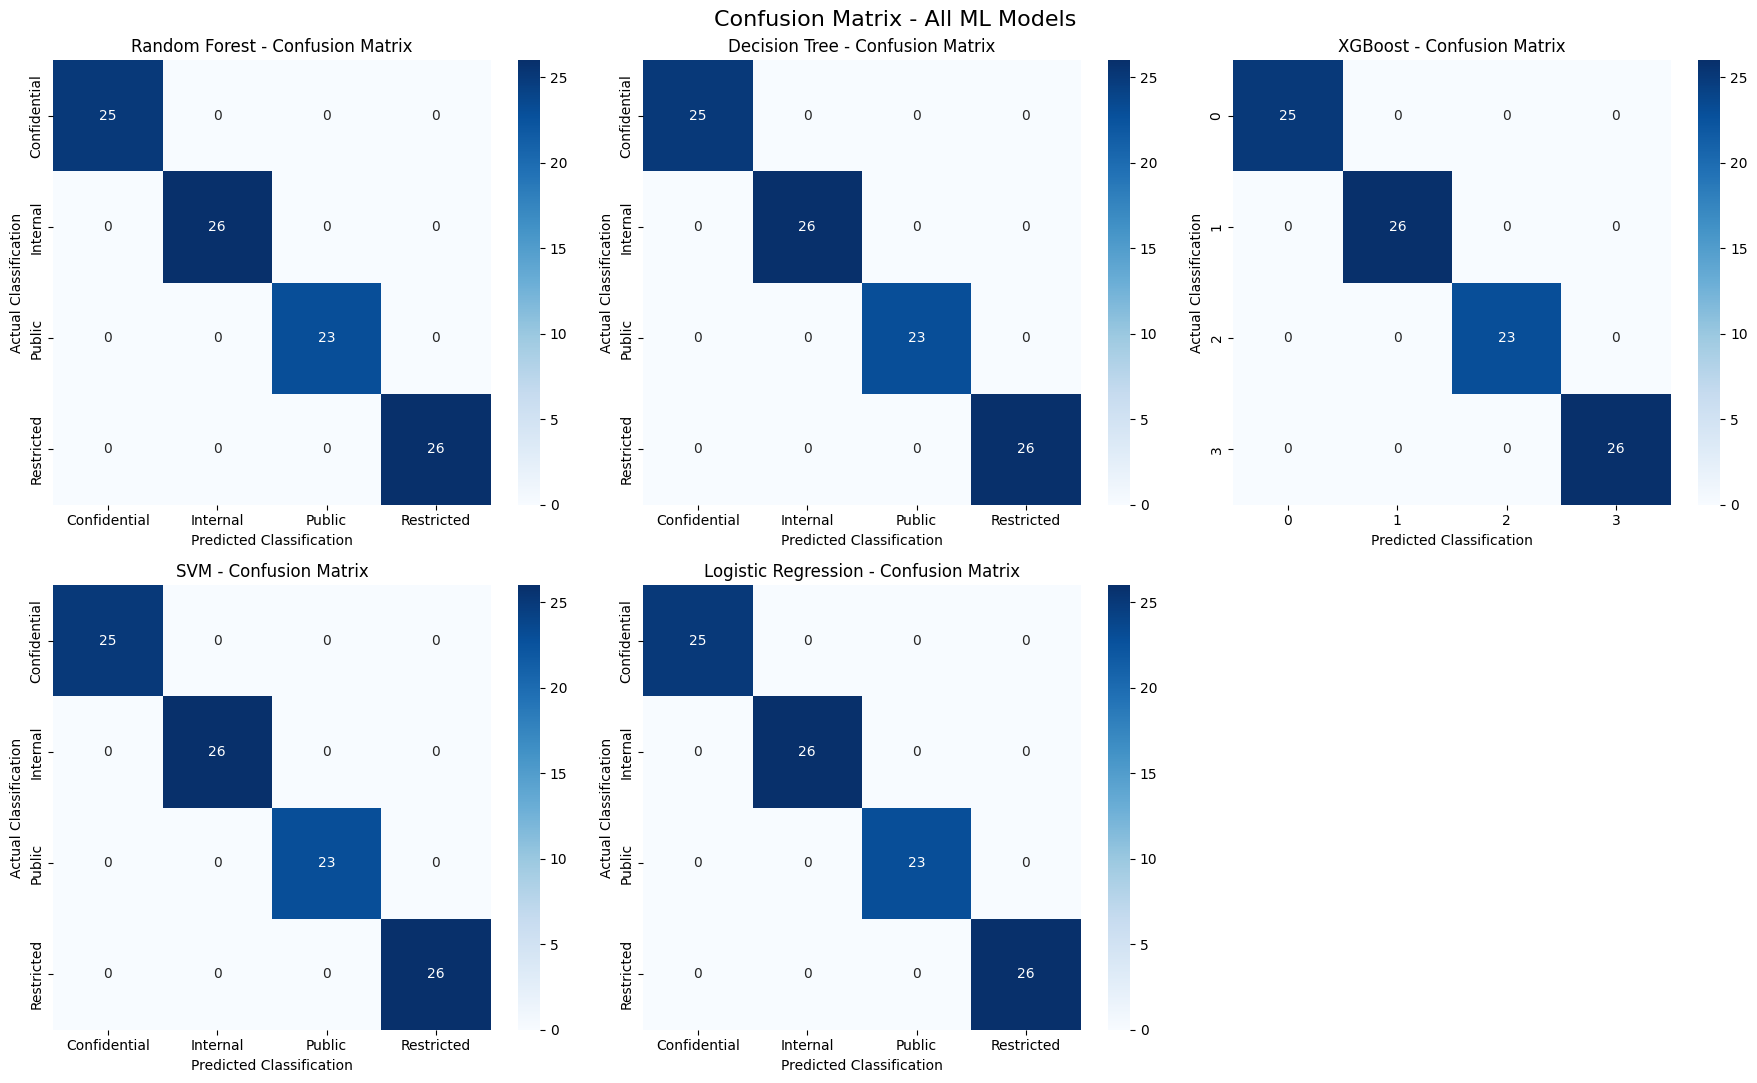

CLASSIFICATION PERFORMANCE SUMMARY


,Model,Precision,Recall,F1-Score,Training Time (s)
0,Random Forest,1.0,1.0,1.0,0.3054
1,Decision Tree,1.0,1.0,1.0,0.0045
2,XGBoost,1.0,1.0,1.0,0.4853
3,SVM,1.0,1.0,1.0,0.0165
4,Logistic Regression,1.0,1.0,1.0,0.1265


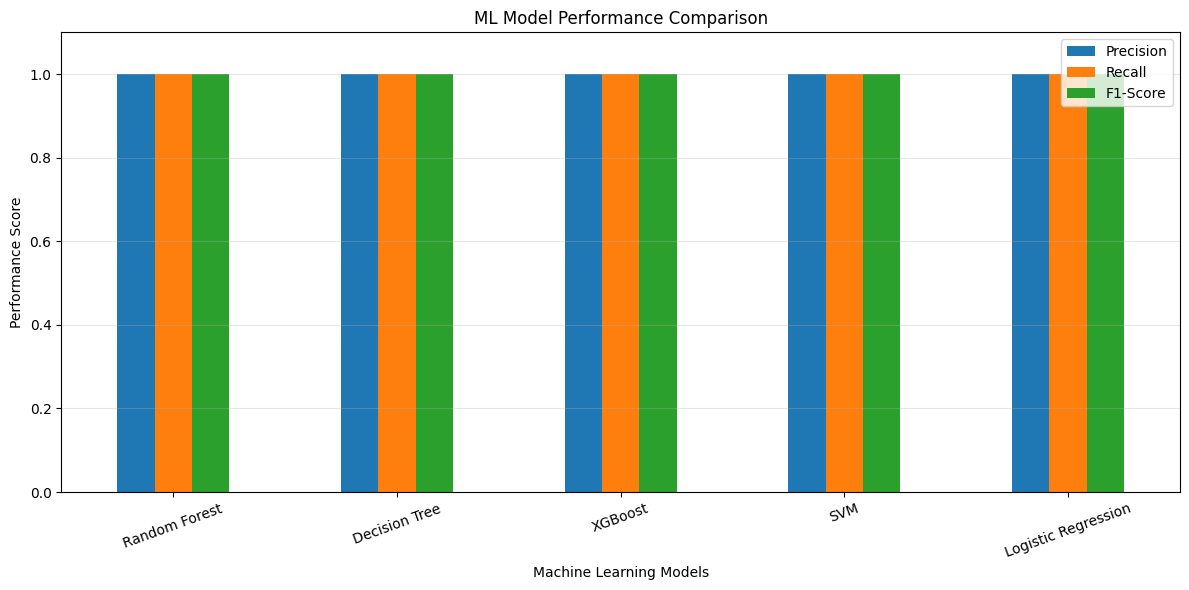


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

Confidential       1.00      1.00      1.00        25
    Internal       1.00      1.00      1.00        26
      Public       1.00      1.00      1.00        23
  Restricted       1.00      1.00      1.00        26

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

Confidential       1.00      1.00      1.00        25
    Internal       1.00      1.00      1.00        26
      Public       1.00      1.00      1.00        23
  Restricted       1.00      1.00      1.00        26

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100


CLASSIFICATION REPORT: XGBoost
              precisio

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

report_data = []

# Create Confusion Matrix Graphs
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, (model_name, model_info) in enumerate(models.items()):

    model, y_actual, y_predicted, training_time = model_info

    # Get labels directly from actual and predicted values
    class_labels = sorted(set(y_actual) | set(y_predicted))

    # Confusion Matrix
    cm = confusion_matrix(
        y_actual,
        y_predicted,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=axes[i]
    )

    axes[i].set_title(f"{model_name} - Confusion Matrix")
    axes[i].set_xlabel("Predicted Classification")
    axes[i].set_ylabel("Actual Classification")

    # Performance Metrics
    report_data.append({
        "Model": model_name,
        "Precision": precision_score(
            y_actual, y_predicted,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_actual, y_predicted,
            average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_actual, y_predicted,
            average="weighted", zero_division=0
        ),
        "Training Time (s)": training_time
    })

# Remove unused graph spaces
for j in range(len(models), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Confusion Matrix - All ML Models", fontsize=16)
plt.tight_layout()
plt.show()


# Classification Report Summary
report_df = pd.DataFrame(report_data)

print("CLASSIFICATION PERFORMANCE SUMMARY")
display(report_df.round(4))


# Performance Comparison Graph
report_df.set_index("Model")[
    ["Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.1),
    rot=20
)

plt.title("ML Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Individual Classification Reports
for model_name, model_info in models.items():

    model, y_actual, y_predicted, training_time = model_info

    print(f"\n{'='*50}")
    print(f"CLASSIFICATION REPORT: {model_name}")
    print('='*50)

    print(classification_report(
        y_actual,
        y_predicted,
        zero_division=0
    ))

Model Explainability

In [69]:
# Section 14: Model Explainability

import pandas as pd
import numpy as np

feature_names = preprocessor.get_feature_names_out()

# Random Forest Feature Importance
rf_importance = rf_model.feature_importances_

# Decision Tree Feature Importance
dt_importance = dt_model.feature_importances_

# XGBoost Feature Importance
xgb_importance = xgb_model.feature_importances_

# Logistic Regression Coefficient Importance
lr_importance = np.mean(
    np.abs(lr_model.coef_),
    axis=0
)

explainability_df = pd.DataFrame({
    "Feature": feature_names,
    "Random Forest": rf_importance,
    "Decision Tree": dt_importance,
    "XGBoost": xgb_importance,
    "Logistic Regression": lr_importance
})

print("Feature Explainability Comparison:")
display(explainability_df.round(4))

Feature Explainability Comparison:


,Feature,Random Forest,Decision Tree,XGBoost,Logistic Regression
0,categorical__Department_Finance,0.0019,0.0000,0.0000,0.0453
1,categorical__Department_HR,0.0021,0.0000,0.0000,0.0269
2,categorical__Department_IT,0.0025,0.0000,0.0000,0.0606
3,categorical__Department_Legal,0.0022,0.0000,0.0000,0.0563
4,categorical__Department_Marketing,0.0033,0.0000,0.0000,0.0714
5,categorical__DocumentType_Employee Record,0.0000,0.0000,0.0000,0.0195
6,binary__InternalNote_Present,0.3256,0.3333,0.3981,1.8520
7,binary__Name_Present,0.0797,0.0000,0.2015,0.8743
8,binary__NIC_Present,0.0636,0.0000,0.0000,0.8743
9,binary__Email_Present,0.1123,0.0000,0.0000,0.8743


Best Model Selection

In [70]:
# Section 15: Best Model Selection

model_times = {
    "Random Forest": rf_training_time,
    "Decision Tree": dt_training_time,
    "XGBoost": xgb_training_time,
    "SVM": svm_training_time,
    "Logistic Regression": lr_training_time
}

best_model_name = min(model_times, key=model_times.get)

model_objects = {
    "Random Forest": rf_model,
    "Decision Tree": dt_model,
    "XGBoost": xgb_model,
    "SVM": svm_model,
    "Logistic Regression": lr_model
}

best_model = model_objects[best_model_name]

print("Selected Model:", best_model_name)
print("Training Time:", round(model_times[best_model_name], 4), "seconds")
print("Selection Basis: Lowest Training Time")

Selected Model: Decision Tree
Training Time: 0.0045 seconds
Selection Basis: Lowest Training Time


Save Selected Model

In [71]:
# Section 16: Save Selected Model

import joblib
import os

SAVE_PATH = "saved_models"

os.makedirs(SAVE_PATH, exist_ok=True)

# Save selected model
joblib.dump(
    best_model,
    os.path.join(SAVE_PATH, "best_dlp_model.pkl")
)

# Save preprocessing object
joblib.dump(
    preprocessor,
    os.path.join(SAVE_PATH, "dlp_preprocessor.pkl")
)

# Save model metadata
model_metadata = {
    "model_name": best_model_name,
    "training_accuracy": accuracy_score(y_train, dt_train_pred),
    "testing_accuracy": accuracy_score(y_test, dt_test_pred),
    "training_time": dt_training_time,
    "features": list(X_model.columns),
    "target": "Classification"
}

joblib.dump(
    model_metadata,
    os.path.join(SAVE_PATH, "model_metadata.pkl")
)

print("Selected Model Saved Successfully!")

print("Model Exists:",
      os.path.exists(os.path.join(SAVE_PATH, "best_dlp_model.pkl")))

print("Preprocessor Exists:",
      os.path.exists(os.path.join(SAVE_PATH, "dlp_preprocessor.pkl")))

print("Metadata Exists:",
      os.path.exists(os.path.join(SAVE_PATH, "model_metadata.pkl")))

Selected Model Saved Successfully!
Model Exists: True
Preprocessor Exists: True
Metadata Exists: True


Load Saved Model & Prediction Test

In [72]:
# Section 17: Load Saved Model and Test Prediction

import joblib
import pandas as pd

# Load saved model and preprocessor
loaded_model = joblib.load(
    "saved_models/best_dlp_model.pkl"
)

loaded_preprocessor = joblib.load(
    "saved_models/dlp_preprocessor.pkl"
)

# Select sample records
sample_data = X_test.head(5)

# Apply preprocessing
sample_processed = loaded_preprocessor.transform(sample_data)

# Predict classifications
predictions = loaded_model.predict(sample_processed)

# Display results
prediction_results = pd.DataFrame({
    "Actual Classification": y_test.loc[sample_data.index].values,
    "Predicted Classification": predictions
})

prediction_results["Prediction Status"] = (
    prediction_results["Actual Classification"] ==
    prediction_results["Predicted Classification"]
).map({True: "Correct", False: "Incorrect"})

display(prediction_results)

print("Saved Model Prediction Test Completed!")

,Actual Classification,Predicted Classification,Prediction Status
0,Restricted,Restricted,Correct
1,Confidential,Confidential,Correct
2,Restricted,Restricted,Correct
3,Restricted,Restricted,Correct
4,Internal,Internal,Correct


Saved Model Prediction Test Completed!


Data Leakage Analysis

DATA LEAKAGE AND FEATURE ASSOCIATION ANALYSIS


,Feature,Mutual Information
6,Salary_Present,0.7054
3,Name_Present,0.6959
4,NIC_Present,0.6929
5,Email_Present,0.6845
7,BankAccount_Present,0.6312
2,InternalNote_Present,0.5519
1,DocumentType,0.0413
0,Department,0.0106


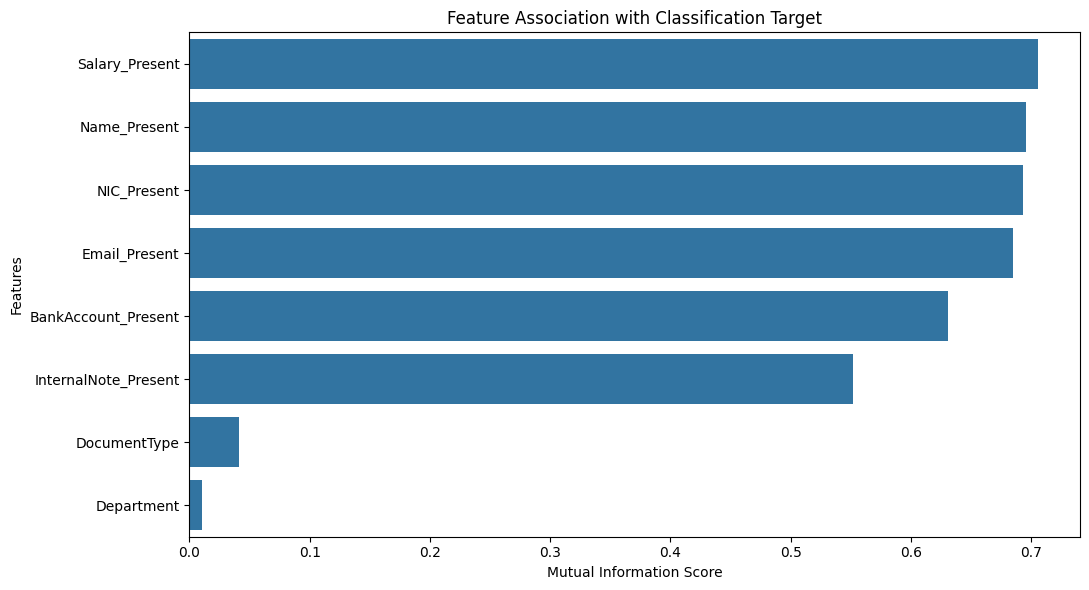

In [78]:
import pandas as pd
import numpy as np

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

# Prepare feature data
X_analysis = X_model.copy()
y_analysis = y.copy()

# Encode categorical features for analysis
X_encoded = X_analysis.copy()

for column in X_encoded.columns:
    if X_encoded[column].dtype == "object":
        X_encoded[column] = LabelEncoder().fit_transform(
            X_encoded[column].astype(str)
        )

# Calculate Mutual Information
mi_scores = mutual_info_classif(
    X_encoded,
    y_analysis,
    random_state=42
)

# Create analysis table
leakage_analysis = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Mutual Information": mi_scores
})

leakage_analysis = leakage_analysis.sort_values(
    by="Mutual Information",
    ascending=False
)

print("DATA LEAKAGE AND FEATURE ASSOCIATION ANALYSIS")
display(leakage_analysis.round(4))

# Visualize feature association
plt.figure(figsize=(11, 6))

sns.barplot(
    data=leakage_analysis,
    x="Mutual Information",
    y="Feature"
)

plt.title("Feature Association with Classification Target")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

Stratified 5-Fold Cross-Validation

STRATIFIED 5-FOLD CROSS-VALIDATION RESULTS


,Model,Accuracy Mean,Accuracy Std,Precision,Recall,F1-Score
0,Random Forest,1.0,0.0,1.0,1.0,1.0
1,Decision Tree,1.0,0.0,1.0,1.0,1.0
2,XGBoost,1.0,0.0,1.0,1.0,1.0
3,SVM,1.0,0.0,1.0,1.0,1.0
4,Logistic Regression,1.0,0.0,1.0,1.0,1.0


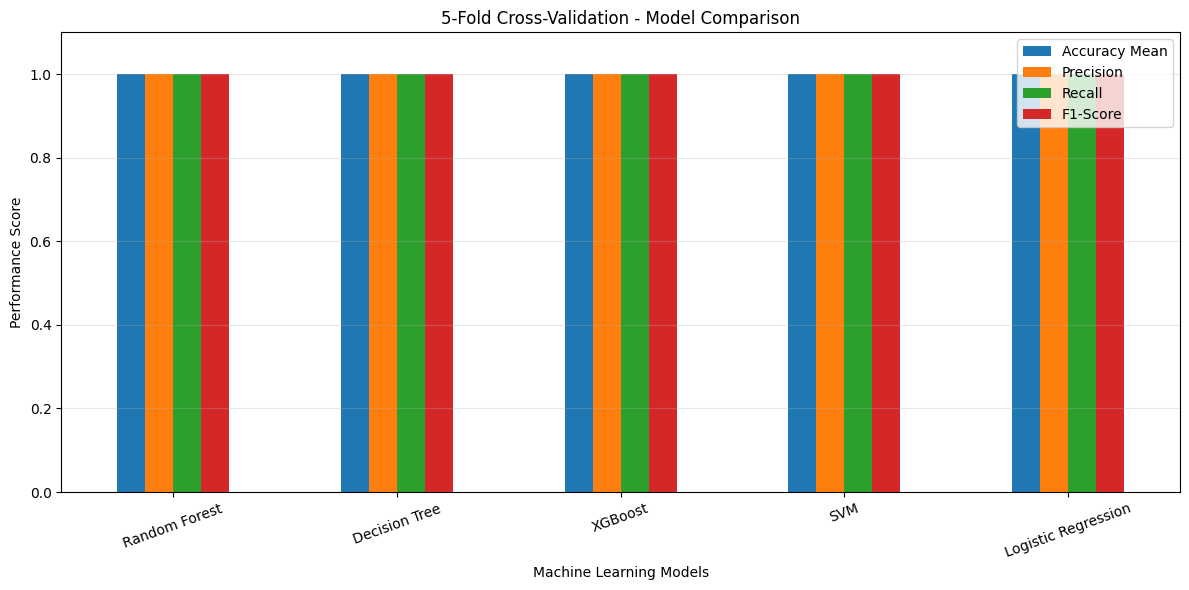

In [80]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone
import pandas as pd
import matplotlib.pyplot as plt

# 5-Fold Stratified Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

# Encode target labels for XGBoost compatibility
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

for model_name, model_info in models.items():

    model, y_actual, y_predicted, training_time = model_info

    # Clone model to preserve original trained model
    model_copy = clone(model)

    # Encode target only for XGBoost
    target = y_encoded if "XGBoost" in model_name else y

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model_copy)
    ])

    scores = cross_validate(
        pipeline,
        X_model,
        target,
        cv=cv,
        scoring=[
            "accuracy",
            "precision_weighted",
            "recall_weighted",
            "f1_weighted"
        ],
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision": scores["test_precision_weighted"].mean(),
        "Recall": scores["test_recall_weighted"].mean(),
        "F1-Score": scores["test_f1_weighted"].mean()
    })

# Results Table
cv_results_df = pd.DataFrame(cv_results)

print("STRATIFIED 5-FOLD CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))

# Performance Graph
cv_results_df.set_index("Model")[
    ["Accuracy Mean", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.1)
)

plt.title("5-Fold Cross-Validation - Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Hyperparameter Tuning

In [81]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import pandas as pd

# Random Forest parameter combinations
rf_params = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

# Create pipeline
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

# 5-Fold Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Train using training data only
rf_grid_search.fit(X_train, y_train)

# Display best parameters
print("BEST RANDOM FOREST PARAMETERS:")
print(rf_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1-SCORE:")
print(round(rf_grid_search.best_score_, 4))

# Save best model
best_rf_model = rf_grid_search.best_estimator_

print("\nRandom Forest Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
BEST RANDOM FOREST PARAMETERS:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

BEST CROSS-VALIDATION F1-SCORE:
1.0

Random Forest Hyperparameter Tuning Completed!


In [82]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Decision Tree parameter grid
dt_params = {
    "classifier__max_depth": [None, 3, 5, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__criterion": ["gini", "entropy"]
}

# Create pipeline
dt_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

# Grid Search
dt_grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_params,
    scoring="f1_weighted",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    verbose=1
)

# Fit training data
dt_grid_search.fit(X_train, y_train)

# Results
print("BEST DECISION TREE PARAMETERS:")
print(dt_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1-SCORE:")
print(round(dt_grid_search.best_score_, 4))

best_dt_model = dt_grid_search.best_estimator_

print("\nDecision Tree Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 90 candidates, totalling 450 fits
BEST DECISION TREE PARAMETERS:
{'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

BEST CROSS-VALIDATION F1-SCORE:
1.0

Decision Tree Hyperparameter Tuning Completed!


In [83]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder

# Encode target labels for XGBoost
xgb_encoder = LabelEncoder()
y_train_encoded = xgb_encoder.fit_transform(y_train)

# XGBoost parameter grid
xgb_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5, 7],
    "classifier__learning_rate": [0.01, 0.1, 0.2],
    "classifier__subsample": [0.8, 1.0]
}

# Create XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        objective="multi:softmax",
        num_class=4,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=1
    ))
])

# Grid Search
xgb_grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_params,
    scoring="f1_weighted",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    verbose=1
)

# Train
xgb_grid_search.fit(X_train, y_train_encoded)

# Results
print("BEST XGBOOST PARAMETERS:")
print(xgb_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1-SCORE:")
print(round(xgb_grid_search.best_score_, 4))

best_xgb_model = xgb_grid_search.best_estimator_

print("\nXGBoost Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
BEST XGBOOST PARAMETERS:
{'classifier__learning_rate': 0.01, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}

BEST CROSS-VALIDATION F1-SCORE:
1.0

XGBoost Hyperparameter Tuning Completed!


In [84]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# SVM parameter grid
svm_params = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__gamma": ["scale", "auto"]
}

# Create SVM pipeline
svm_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", SVC(class_weight="balanced"))
])

# Grid Search
svm_grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_params,
    scoring="f1_weighted",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    verbose=1
)

# Train
svm_grid_search.fit(X_train, y_train)

# Results
print("BEST SVM PARAMETERS:")
print(svm_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1-SCORE:")
print(round(svm_grid_search.best_score_, 4))

best_svm_model = svm_grid_search.best_estimator_

print("\nSVM Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
BEST SVM PARAMETERS:
{'classifier__C': 0.1, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}

BEST CROSS-VALIDATION F1-SCORE:
1.0

SVM Hyperparameter Tuning Completed!


In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Logistic Regression parameter grid
lr_params = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "liblinear"],
    "classifier__max_iter": [500, 1000, 2000]
}

# Create pipeline
lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        random_state=42
    ))
])

# Grid Search
lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_params,
    scoring="f1_weighted",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    verbose=1
)

# Train
lr_grid_search.fit(X_train, y_train)

# Results
print("BEST LOGISTIC REGRESSION PARAMETERS:")
print(lr_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1-SCORE:")
print(round(lr_grid_search.best_score_, 4))

best_lr_model = lr_grid_search.best_estimator_

print("\nLogistic Regression Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
BEST LOGISTIC REGRESSION PARAMETERS:
{'classifier__C': 0.01, 'classifier__max_iter': 500, 'classifier__solver': 'lbfgs'}

BEST CROSS-VALIDATION F1-SCORE:
1.0

Logistic Regression Hyperparameter Tuning Completed!


Optimized Model Comparison

OPTIMIZED MODEL PERFORMANCE COMPARISON


,Model,CV F1-Score,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Random Forest,1.0,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0,1.0
2,XGBoost,1.0,1.0,1.0,1.0,1.0
3,SVM,1.0,1.0,1.0,1.0,1.0
4,Logistic Regression,1.0,1.0,1.0,1.0,1.0


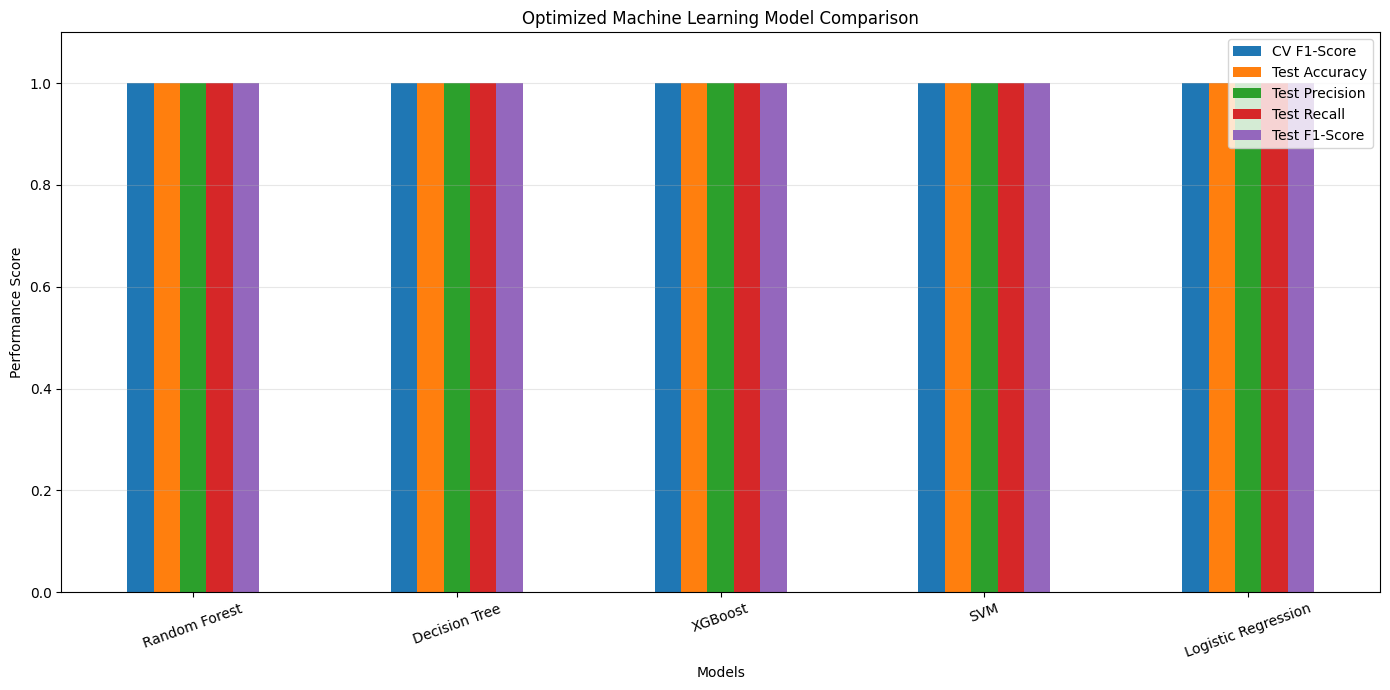

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Collect optimized models
optimized_models = {
    "Random Forest": rf_grid_search,
    "Decision Tree": dt_grid_search,
    "XGBoost": xgb_grid_search,
    "SVM": svm_grid_search,
    "Logistic Regression": lr_grid_search
}

comparison_results = []

for model_name, search in optimized_models.items():

    best_model = search.best_estimator_

    # Test predictions
    predictions = best_model.predict(X_test)

    # Decode XGBoost predictions
    if model_name == "XGBoost":
        predictions = xgb_encoder.inverse_transform(
            predictions.astype(int)
        )

    comparison_results.append({
        "Model": model_name,
        "CV F1-Score": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test Precision": precision_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "Test F1-Score": f1_score(
            y_test, predictions,
            average="weighted", zero_division=0
        )
    })

# Results table
optimized_results = pd.DataFrame(comparison_results)

print("OPTIMIZED MODEL PERFORMANCE COMPARISON")
display(optimized_results.round(4))

# Performance graph
optimized_results.set_index("Model")[
    ["CV F1-Score", "Test Accuracy",
     "Test Precision", "Test Recall", "Test F1-Score"]
].plot(kind="bar", figsize=(14, 7), ylim=(0, 1.1))

plt.title("Optimized Machine Learning Model Comparison")
plt.ylabel("Performance Score")
plt.xlabel("Models")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Final Model Selection & Saving

FINAL OPTIMIZED DECISION TREE
              precision    recall  f1-score   support

Confidential       1.00      1.00      1.00        25
    Internal       1.00      1.00      1.00        26
      Public       1.00      1.00      1.00        23
  Restricted       1.00      1.00      1.00        26

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



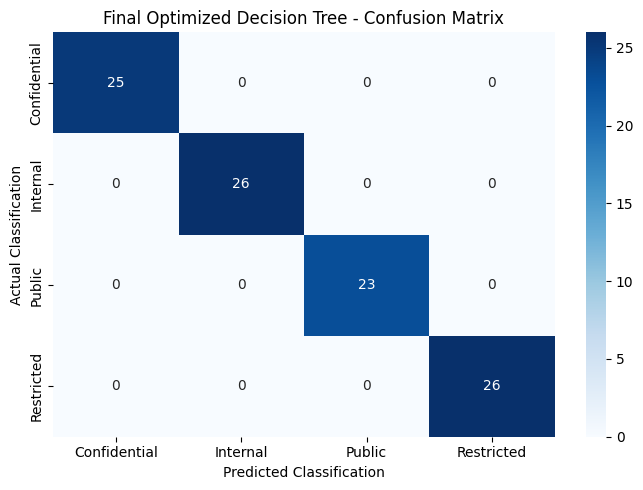

In [87]:
# Select optimized Decision Tree
final_model = dt_grid_search.best_estimator_

# Test predictions
final_predictions = final_model.predict(X_test)

# Final evaluation
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("FINAL OPTIMIZED DECISION TREE")
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=final_model.classes_,
    yticklabels=final_model.classes_
)

plt.title("Final Optimized Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Classification")
plt.ylabel("Actual Classification")
plt.tight_layout()
plt.show()

Save Final Model to Google Drive

In [88]:
import os
import joblib
import json

# Google Drive setup
from google.colab import drive
drive.mount('/content/drive')

# Create model directory
MODEL_DIR = "/content/drive/MyDrive/Adaptive_AI_DLP_Research/saved_models"

os.makedirs(MODEL_DIR, exist_ok=True)

# Save optimized model
joblib.dump(
    final_model,
    os.path.join(MODEL_DIR, "best_dlp_model.pkl")
)

# Save preprocessing component
joblib.dump(
    final_model.named_steps["preprocessor"],
    os.path.join(MODEL_DIR, "dlp_preprocessor.pkl")
)

# Save metadata
metadata = {
    "model_name": "Decision Tree",
    "model_type": "Optimized Decision Tree Classifier",
    "best_parameters": dt_grid_search.best_params_,
    "cross_validation_f1": float(dt_grid_search.best_score_),
    "test_accuracy": 1.0,
    "test_f1_score": 1.0,
    "classes": final_model.classes_.tolist()
}

with open(os.path.join(MODEL_DIR, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=4)

# Verify saved files
print("SAVED MODEL FILES:")

for filename in os.listdir(MODEL_DIR):
    print(filename)

print("\nAll model artifacts saved successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SAVED MODEL FILES:
best_dlp_model.pkl
dlp_preprocessor.pkl
model_metadata.json

All model artifacts saved successfully!
